# 03 · An electric vehicle

Same house, now with a 40 kWh EV and a 3.7 kW home charger. The car leaves every day at 08:30 and is back at
18:00 with 40 % SOC; the owner wants at least 80 % before leaving. While the car is away its SOC is not tracked.

The reference is a dumb charger that charges at full power as soon as the car is plugged in. In the model that
reference is simply a fixed `Load` with the profile returned by `ElectricVehicle.charge_on_arrival()`.

In [1]:
import sys
from pathlib import Path

# make the package importable without installing it (the notebooks live one level below the repo root)
src = Path().resolve().parent / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

import pandas as pd
pd.set_option("display.precision", 3)

In [2]:
from fennec import Load, SmartHome
from fennec.examples import default_horizon, electric_vehicle, porto_grid, porto_load, porto_pv, porto_vehicle
from fennec.utils import compare, energy_balance, plot_comparison, plot_dispatch

horizon = default_horizon()
grid, pv, house, car = porto_grid(), porto_pv(horizon), porto_load(horizon), porto_vehicle(horizon)

# a 3.7 kW charger on top of the evening peak exceeds the 6.9 kW contracted power, so the dumb charger is
# capped by what is left once the house is served (what a charger with dynamic load management does)
available = [horizon.energy(grid.contracted_power_kw) + p - l for p, l in zip(pv.energy, house.energy)]
dumb = Load("car_on_arrival", energy=car.charge_on_arrival(horizon, max_energy=available))
reference = SmartHome(horizon, grid, [pv, house, dumb])

results = {
    "charge on arrival": reference.solve(),
    "optimized": electric_vehicle(horizon).solve(time_limit=120),
}
compare(results, reference="charge on arrival")

,status,bill,stored_value,objective,import_kwh,export_kwh,solve_s,commands,saving,saving_pct
charge on arrival,optimal,14.403,0.0,14.403,107.29,16.06,0.01,NaN,0.000,0.0
optimized,optimal,11.724,0.0,11.727,91.91,16.06,0.04,3.0,2.676,18.6


The optimized charger waits for the cheap night rate and still meets the 80 % target before the 08:30 departure.
Note that the second day only has PV before noon, so the midday surplus of the first day is the only chance to
charge with free energy; with the car away at that time nothing can be done about it.

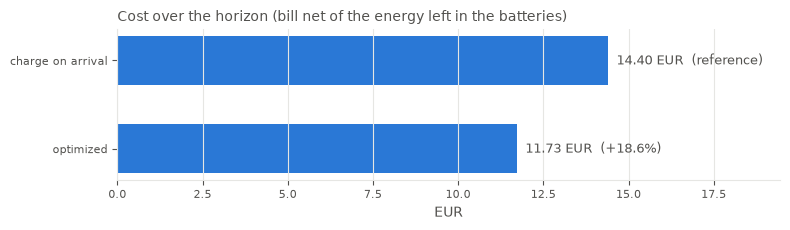

In [3]:
plot_comparison(results, reference="charge on arrival");

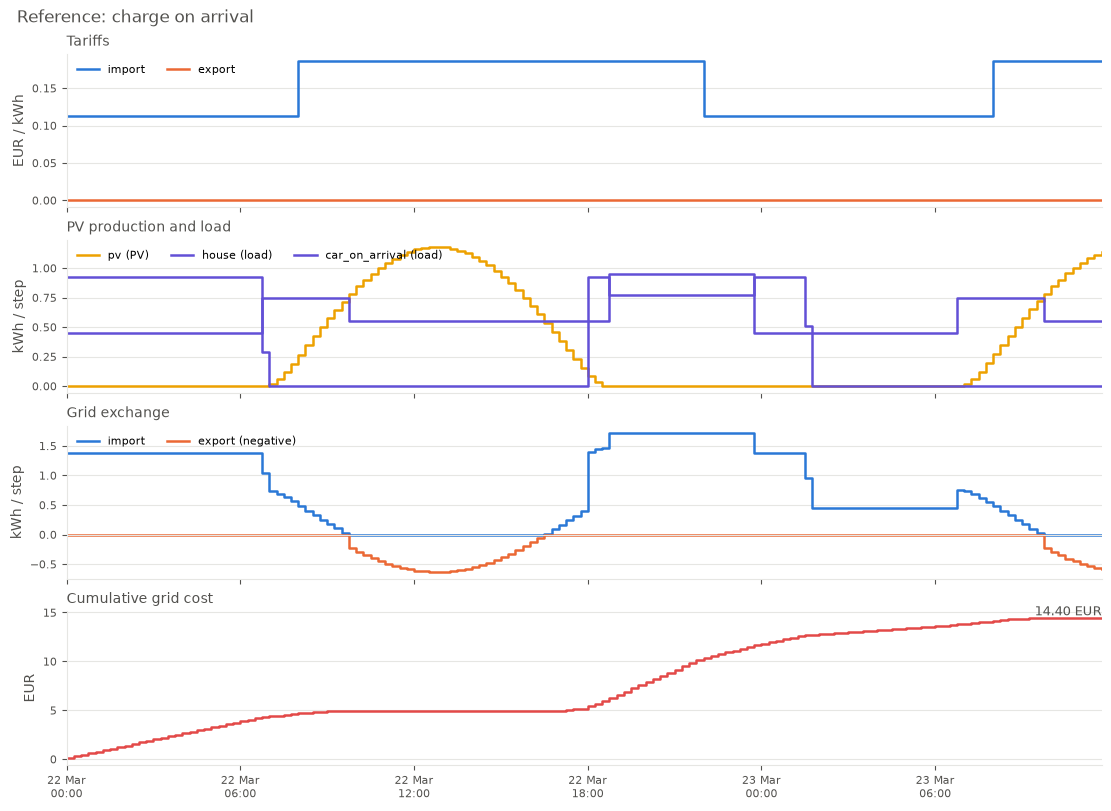

In [4]:
plot_dispatch(results["charge on arrival"], title="Reference: charge on arrival");

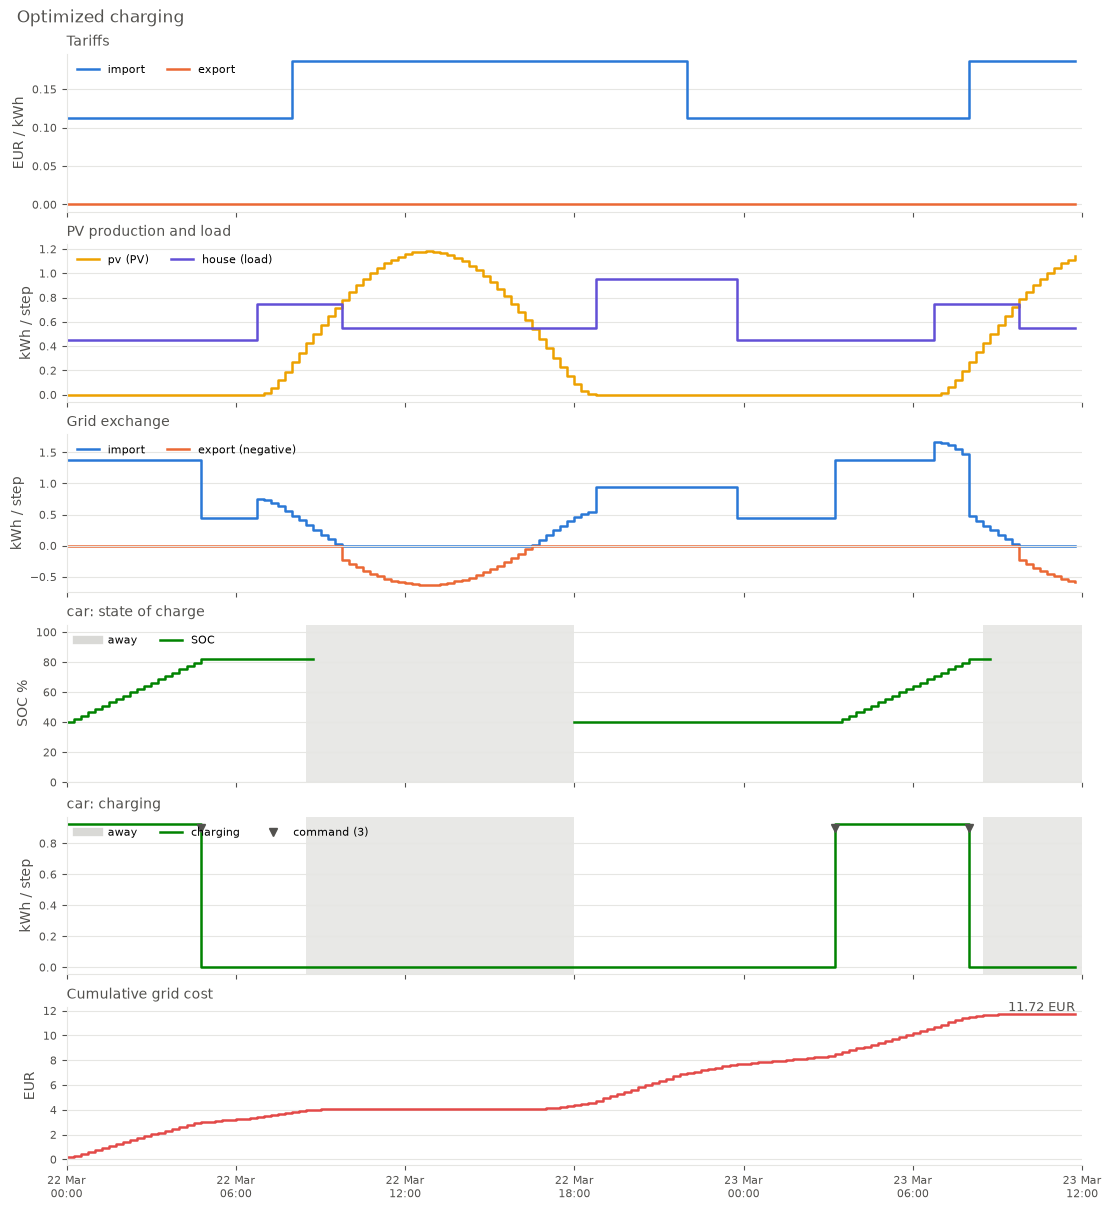

In [5]:
plot_dispatch(results["optimized"], title="Optimized charging");

## Soft targets

The SOC target is a *soft* constraint: missing percentage points are penalised by `target_penalty`, so a target that
cannot be reached (a short stop, a weak charger) does not make the problem infeasible. The penalty shows up in
the car's own cost column.

In [6]:
energy_balance(results["optimized"])

,kind,to_house_kwh,from_house_kwh,cost
asset,,,,
grid,grid,91.909,16.059,11.724
pv,pv,45.800,0.000,0.000
house,load,0.000,86.500,0.000
car,ev,0.000,35.150,0.003
